# KNN Model

In [3]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
import seaborn as sns

# Step 1: Load the dataset
dataset = pd.read_csv("dataset_7.csv")
print("First five rows of the dataset:")
print(dataset.head())  # Display the first few rows of the dataset
print("\nDataset Information:")
print(dataset.info())  # Display information about the dataset

# Separate features (X) and labels (y)
y = dataset.iloc[:, 0]  # Labels (first column)
x = dataset.iloc[:, 1:]  # Features (remaining columns)
print("\nSample labels:")
print(y.head())
print("\nSample features:")
print(x.sample(10))

First five rows of the dataset:
   label  1x1  1x2  1x3  1x4  1x5  1x6  1x7  1x8  1x9  ...  28x19  28x20  \
0      5    0    0    0    0    0    0    0    0    0  ...      0      0   
1      0    0    0    0    0    0    0    0    0    0  ...      0      0   
2      4    0    0    0    0    0    0    0    0    0  ...      0      0   
3      1    0    0    0    0    0    0    0    0    0  ...      0      0   
4      9    0    0    0    0    0    0    0    0    0  ...      0      0   

   28x21  28x22  28x23  28x24  28x25  28x26  28x27  28x28  
0      0      0      0      0      0      0      0      0  
1      0      0      0      0      0      0      0      0  
2      0      0      0      0      0      0      0      0  
3      0      0      0      0      0      0      0      0  
4      0      0      0      0      0      0      0      0  

[5 rows x 785 columns]

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Columns: 785 entries, label t

In [40]:
# Step 2: Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=75)

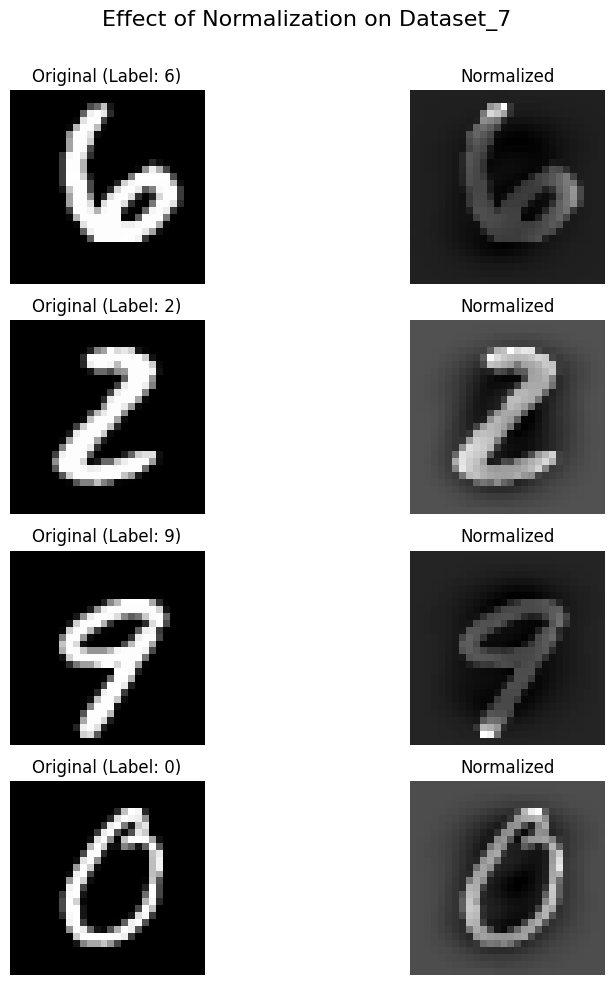

In [41]:
# Step 3: Normalize the features using StandardScaler
scaler = StandardScaler()
X_train_normalized = scaler.fit_transform(X_train)  # Fit on training data
X_test_normalized = scaler.transform(X_test)       # Transform test data

# Step 4: Visualize the effect of normalization on sample images
samples = [0, 1, 2, 3]  # Indices of sample rows to visualize
image_shape = (28, 28)  # Assumed image shape (28x28 for MNIST-like dataset)

fig, axes = plt.subplots(nrows=len(samples), ncols=2, figsize=(10, 10))
fig.suptitle("Effect of Normalization on Dataset_7", fontsize=16)

for i, sample_idx in enumerate(samples):
    # Original image (before normalization)
    original_image = X_train.iloc[sample_idx].values.reshape(image_shape)
    axes[i, 0].imshow(original_image, cmap='gray')
    axes[i, 0].set_title(f"Original (Label: {y_train.iloc[sample_idx]})")
    axes[i, 0].axis('off')

    # Normalized image (after scaling)
    normalized_image = X_train_normalized[sample_idx].reshape(image_shape)
    axes[i, 1].imshow(normalized_image, cmap='gray')
    axes[i, 1].set_title("Normalized")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.9)
plt.show()

In [42]:
# Step 5: Train a K-Nearest Neighbors (KNN) Classifier
# Initialize classifier with default neighbors
classifier = KNeighborsClassifier(n_neighbors=5)
classifier.fit(X_train_normalized, y_train)

# Evaluate KNN classifier using a range of K values
error = []
for i in range(1, 20):
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(X_train_normalized, y_train)
    pred_i = knn.predict(X_test_normalized)
    error.append(np.mean(pred_i != y_test))

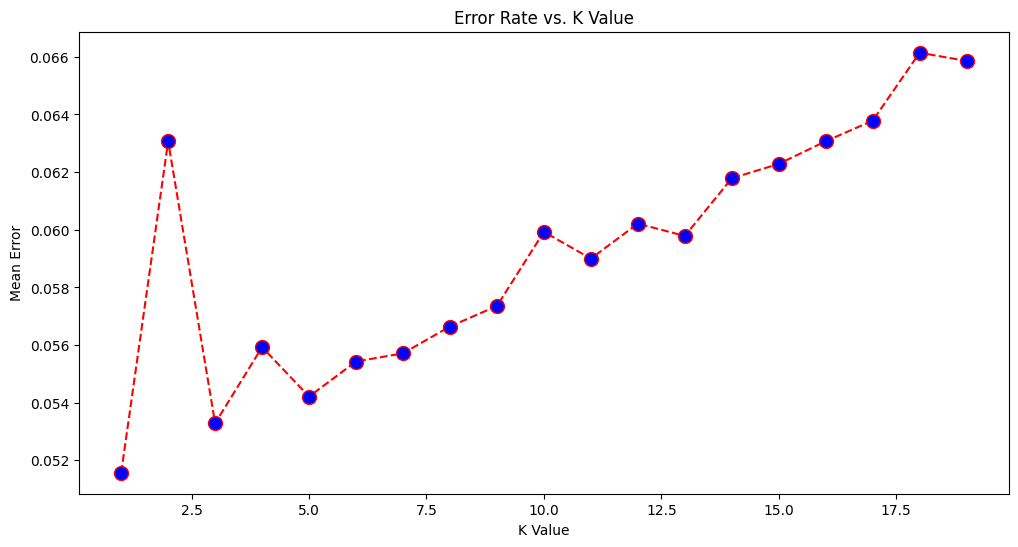

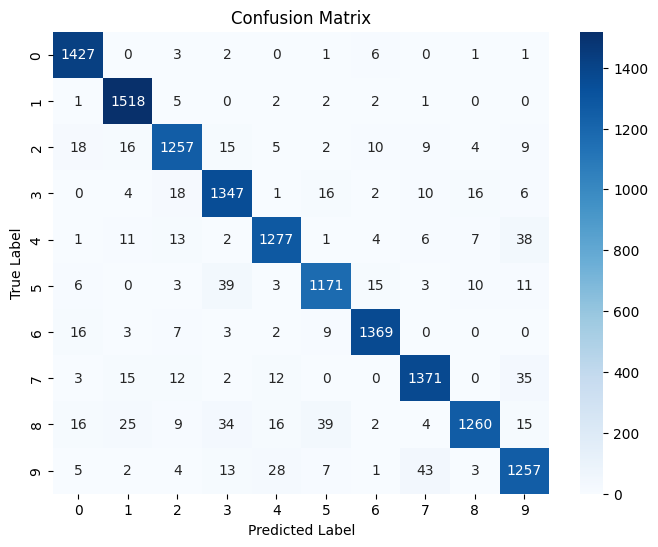

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.99      0.97      1441
           1       0.95      0.99      0.97      1531
           2       0.94      0.93      0.94      1345
           3       0.92      0.95      0.94      1420
           4       0.95      0.94      0.94      1360
           5       0.94      0.93      0.93      1261
           6       0.97      0.97      0.97      1409
           7       0.95      0.95      0.95      1450
           8       0.97      0.89      0.93      1420
           9       0.92      0.92      0.92      1363

    accuracy                           0.95     14000
   macro avg       0.95      0.95      0.95     14000
weighted avg       0.95      0.95      0.95     14000

Accuracy: 0.9467142857142857

Cross-Validation Scores: [0.94383929 0.94142857 0.94482143 0.94348214 0.94223214]
Mean Accuracy: 0.9431607142857142


In [43]:
# Plot error rate for different K values
plt.figure(figsize=(12, 6))
plt.plot(range(1, 20), error, color='red', linestyle='dashed', marker='o',
         markerfacecolor='blue', markersize=10)
plt.title('Error Rate vs. K Value')
plt.xlabel('K Value')
plt.ylabel('Mean Error')
plt.show()

# Train final KNN model with 3 neighbors
classifier = KNeighborsClassifier(n_neighbors=3)
classifier.fit(X_train_normalized, y_train)

# Predict on the test set
y_pred = classifier.predict(X_test_normalized)

# Step 6: Evaluate Model Performance
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# Classification Report and Accuracy
print("Classification Report:\n", classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))

# Cross-Validation for KNN
scores = cross_val_score(classifier, X_train_normalized, y_train, cv=5)
print("\nCross-Validation Scores:", scores)
print("Mean Accuracy:", scores.mean())


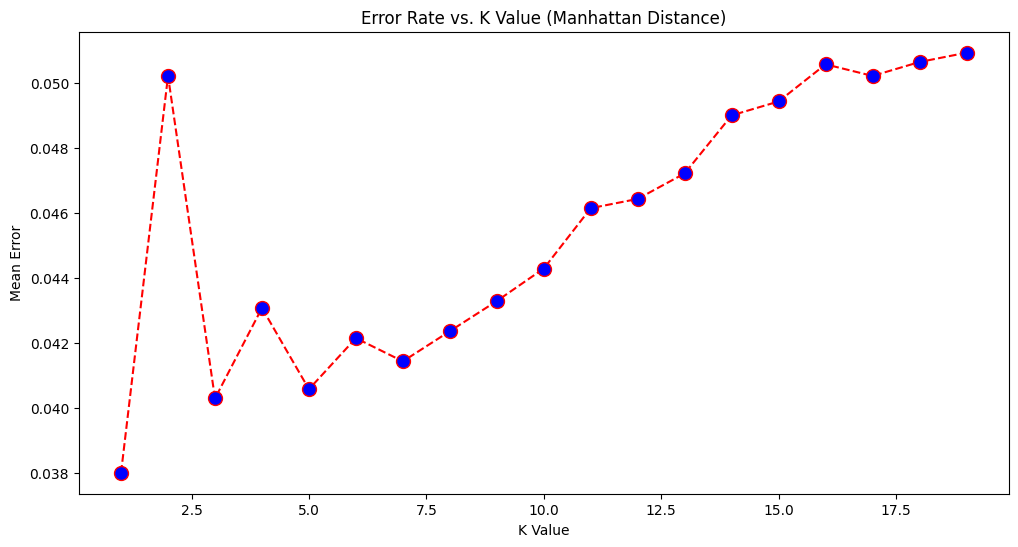

In [44]:
# Step 7: KNN with Manhattan Distance
error_manhattan = []
for i in range(1, 20):
    knn = KNeighborsClassifier(n_neighbors=i, metric='manhattan')
    knn.fit(X_train_normalized, y_train)
    pred_i = knn.predict(X_test_normalized)
    error_manhattan.append(np.mean(pred_i != y_test))

# Plot error rate for Manhattan distance
plt.figure(figsize=(12, 6))
plt.plot(range(1, 20), error_manhattan, color='red', linestyle='dashed', marker='o',
         markerfacecolor='blue', markersize=10)
plt.title('Error Rate vs. K Value (Manhattan Distance)')
plt.xlabel('K Value')
plt.ylabel('Mean Error')
plt.show()

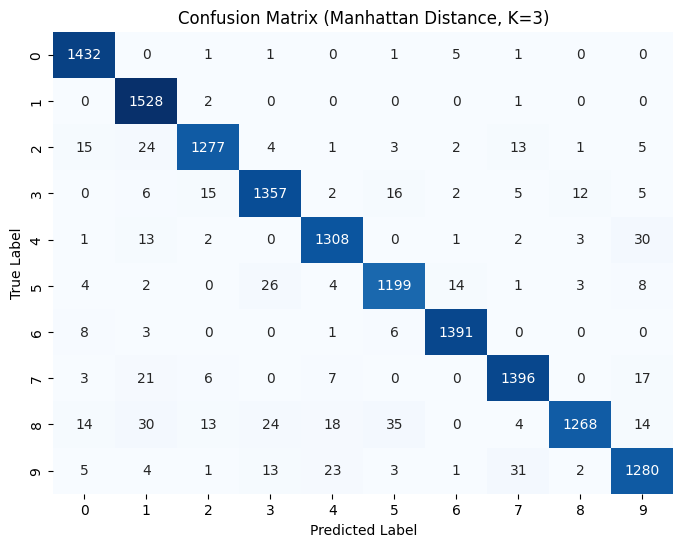

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.99      0.98      1441
           1       0.94      1.00      0.97      1531
           2       0.97      0.95      0.96      1345
           3       0.95      0.96      0.95      1420
           4       0.96      0.96      0.96      1360
           5       0.95      0.95      0.95      1261
           6       0.98      0.99      0.98      1409
           7       0.96      0.96      0.96      1450
           8       0.98      0.89      0.94      1420
           9       0.94      0.94      0.94      1363

    accuracy                           0.96     14000
   macro avg       0.96      0.96      0.96     14000
weighted avg       0.96      0.96      0.96     14000

Accuracy: 0.9597142857142857
Cross-Validation Scores: [0.95857143 0.95678571 0.9625     0.95723214 0.95732143]
Mean Accuracy: 0.9584821428571428


In [45]:
# Train KNN Classifier using Manhattan distance metric
classifier = KNeighborsClassifier(n_neighbors=3, metric='manhattan')
classifier.fit(X_train_normalized, y_train)

# Make predictions on the test set
y_pred = classifier.predict(X_test_normalized)

# Step 1: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Confusion Matrix (Manhattan Distance, K=3)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# Step 2: Classification Metrics
# Display classification report
print("Classification Report:\n", classification_report(y_test, y_pred))

# Calculate and display accuracy
KNN_accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", KNN_accuracy)

# Step 3: Cross-Validation
# Perform 5-fold cross-validation to evaluate model performance
scores = cross_val_score(classifier, X_train_normalized, y_train, cv=5)

# Display cross-validation scores and their mean
print("Cross-Validation Scores:", scores)
print("Mean Accuracy:", scores.mean())


# SVM Model

In [21]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# Step 1: Load the dataset
dataset = pd.read_csv("dataset_7.csv")
y = dataset.iloc[:, 0]  # Labels
X = dataset.iloc[:, 1:]  # Features

# Step 2: Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=75)

# Step 3: Normalize the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 4: Dimensionality reduction using PCA
pca = PCA(n_components=50)  # Reduce features to 50 principal components
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [22]:
# Step 5: Test different SVM margin settings using a sample of the dataset
# Subset the data for demonstration purposes
sample_size = 5000  # Use 10,000 samples
X_train_sample = X_train_pca[:sample_size]
y_train_sample = y_train[:sample_size]

# ## Hard Margin SVM
# svm_hard = SVC(C=1000, kernel='linear')  # Reduced C to demonstrate hard margin
# svm_hard.fit(X_train_sample, y_train_sample)
# print(f"Support vectors (Hard Margin): {len(svm_hard.support_)}")

# ## Soft Margin SVM
# svm_soft = SVC(C=0.1, kernel='linear')  # Lower C provides a softer margin
# svm_soft.fit(X_train_sample, y_train_sample)
# print(f"Support vectors (Soft Margin): {len(svm_soft.support_)}")



In [3]:
# Ensure all vector elements are displayed
np.set_printoptions(threshold=np.inf)

# Print all support vectors for Hard and Soft Margin SVM
print("Support vectors (Hard Margin):", svm_hard.support_)
print("Support vectors (Soft Margin):", svm_soft.support_)

# Reset NumPy print options (optional, to avoid affecting other parts of your code)
np.set_printoptions(threshold=1000)  # Default threshold

Support vectors (Hard Margin): [ 264  336  386  526  531  541  563  638  640  653  679  705  788  819
  832  870 1047 1291 1294 1310 1329 1392 1398 1428 1656 1768 1778 1845
 1852 1900 1927 1946 1951 2003 2030 2212 2302 2337 2342 2406 2449 2699
 2759 2777 2912 2993 3086 3109 3192 3198 3209 3333 3335 3375 3427 3447
 3555 3602 3620 3793 3882 3912 3938 4038 4070 4079 4198 4503 4519 4525
 4561 4587 4639 4727 4837 4959   65  224  238  447  648  722  779  997
 1108 1113 1250 1581 1740 1801 1811 1924 1949 2035 2049 2166 2339 2662
 2697 2863 2881 2906 2979 2998 2999 3208 3505 3762 3802 3941 3948 4063
 4153 4165 4182 4209 4319 4530 4537 4584 4588 4635 4709 4917    3  176
  234  243  275  306  331  350  356  367  458  551  574  580  597  600
  656  678  749  799  857  914 1073 1181 1270 1372 1419 1441 1453 1477
 1495 1531 1535 1538 1555 1582 1703 1764 1857 1863 1936 1953 1955 1998
 2020 2031 2041 2045 2102 2133 2172 2173 2178 2188 2198 2214 2392 2443
 2467 2572 2643 2650 2670 2691 2829 2854 2871 

Linear Kernel - Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.96      0.94      1441
           1       0.94      0.97      0.95      1531
           2       0.90      0.88      0.89      1345
           3       0.86      0.88      0.87      1420
           4       0.89      0.93      0.91      1360
           5       0.86      0.88      0.87      1261
           6       0.95      0.95      0.95      1409
           7       0.93      0.91      0.92      1450
           8       0.89      0.80      0.84      1420
           9       0.88      0.87      0.88      1363

    accuracy                           0.90     14000
   macro avg       0.90      0.90      0.90     14000
weighted avg       0.90      0.90      0.90     14000

Linear Kernel - Accuracy: 0.9027857142857143


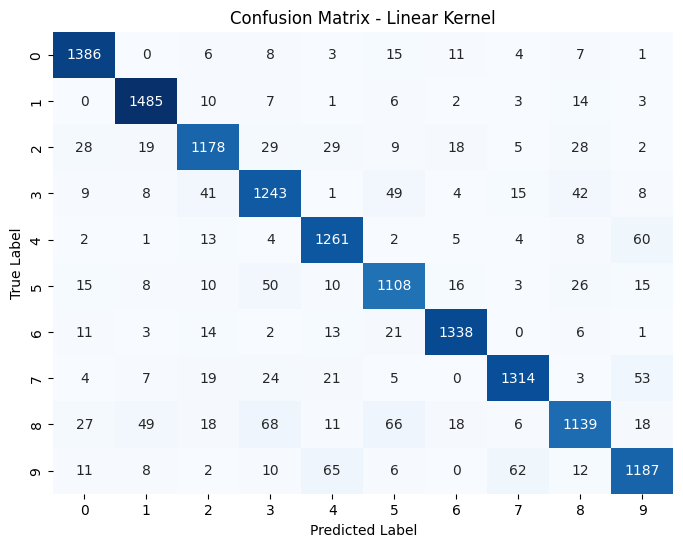

In [23]:
# Step 6: Test different SVM kernel types
## Linear Kernel
svm_linear = SVC(kernel='linear', C=1.0)
svm_linear.fit(X_train_sample, y_train_sample)
y_pred_linear = svm_linear.predict(X_test_pca)

# Evaluate Linear Kernel
print("Linear Kernel - Classification Report:\n", classification_report(y_test, y_pred_linear))
print("Linear Kernel - Accuracy:", accuracy_score(y_test, y_pred_linear))

# Confusion Matrix for Linear Kernel
cm_linear = confusion_matrix(y_test, y_pred_linear)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_linear, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Confusion Matrix - Linear Kernel")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


RBF Kernel - Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.98      0.97      1441
           1       0.96      0.98      0.97      1531
           2       0.93      0.94      0.93      1345
           3       0.92      0.92      0.92      1420
           4       0.94      0.94      0.94      1360
           5       0.94      0.93      0.94      1261
           6       0.96      0.98      0.97      1409
           7       0.91      0.93      0.92      1450
           8       0.94      0.90      0.92      1420
           9       0.90      0.89      0.90      1363

    accuracy                           0.94     14000
   macro avg       0.94      0.94      0.94     14000
weighted avg       0.94      0.94      0.94     14000

RBF Kernel - Accuracy: 0.9388571428571428


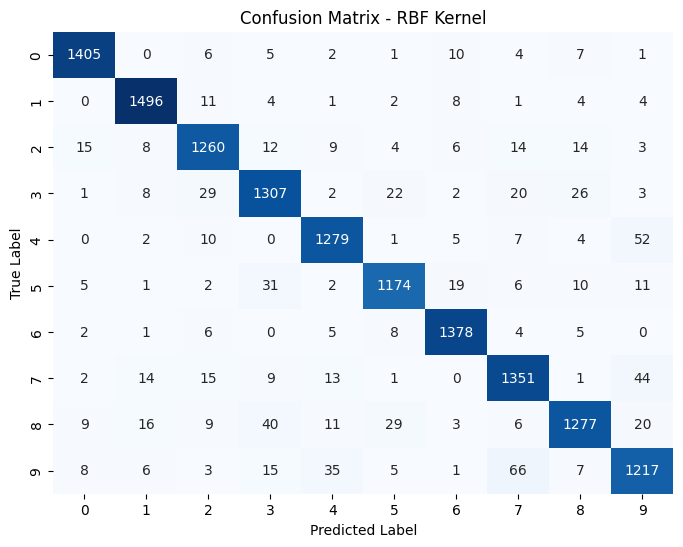

In [24]:
## RBF Kernel
svm_rbf = SVC(kernel='rbf', C=1.0, gamma='scale')
svm_rbf.fit(X_train_sample, y_train_sample)
y_pred_rbf = svm_rbf.predict(X_test_pca)

# Evaluate RBF Kernel
print("RBF Kernel - Classification Report:\n", classification_report(y_test, y_pred_rbf))
print("RBF Kernel - Accuracy:", accuracy_score(y_test, y_pred_rbf))

# Confusion Matrix for RBF Kernel
cm_rbf = confusion_matrix(y_test, y_pred_rbf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rbf, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Confusion Matrix - RBF Kernel")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

Polynomial Kernel - Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.94      0.96      1441
           1       0.98      0.97      0.98      1531
           2       0.95      0.86      0.91      1345
           3       0.94      0.85      0.89      1420
           4       0.90      0.93      0.91      1360
           5       0.94      0.87      0.90      1261
           6       0.98      0.93      0.96      1409
           7       0.96      0.87      0.91      1450
           8       0.71      0.94      0.81      1420
           9       0.83      0.92      0.87      1363

    accuracy                           0.91     14000
   macro avg       0.92      0.91      0.91     14000
weighted avg       0.92      0.91      0.91     14000

Polynomial Kernel - Accuracy: 0.9085714285714286


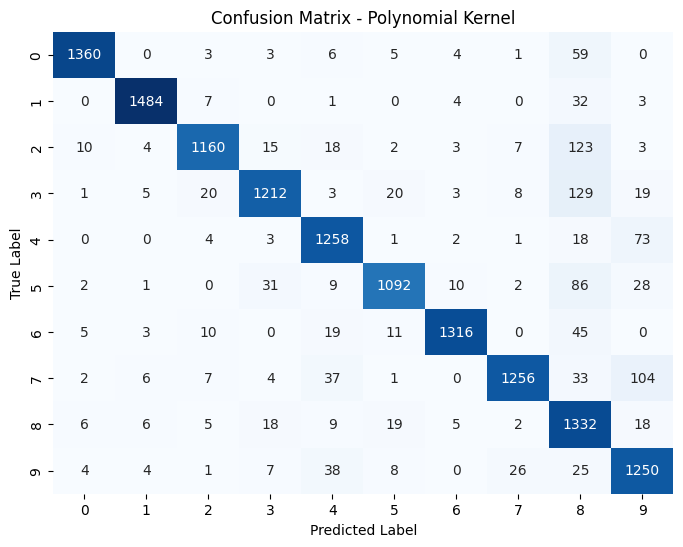

In [25]:
## Polynomial Kernel
svm_poly = SVC(kernel='poly', C=1.0, degree=3)
svm_poly.fit(X_train_sample, y_train_sample)
y_pred_poly = svm_poly.predict(X_test_pca)

# Evaluate Polynomial Kernel
print("Polynomial Kernel - Classification Report:\n", classification_report(y_test, y_pred_poly))
print("Polynomial Kernel - Accuracy:", accuracy_score(y_test, y_pred_poly))

# Confusion Matrix for Polynomial Kernel
cm_poly = confusion_matrix(y_test, y_pred_poly)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_poly, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Confusion Matrix - Polynomial Kernel")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

Final Model - Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99      1441
           1       0.98      0.98      0.98      1531
           2       0.95      0.96      0.96      1345
           3       0.97      0.95      0.96      1420
           4       0.95      0.96      0.96      1360
           5       0.97      0.96      0.97      1261
           6       0.98      0.98      0.98      1409
           7       0.93      0.97      0.95      1450
           8       0.97      0.96      0.96      1420
           9       0.96      0.94      0.95      1363

    accuracy                           0.97     14000
   macro avg       0.97      0.97      0.97     14000
weighted avg       0.97      0.97      0.97     14000

Final Model - Accuracy: 0.9662142857142857


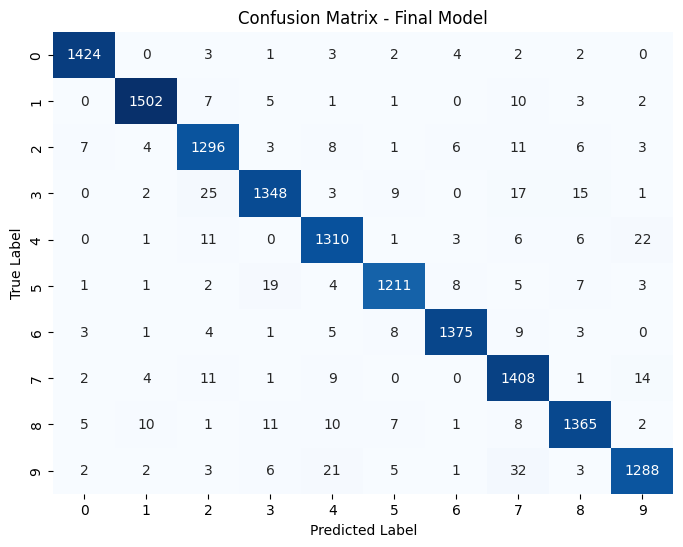

Cross-Validation Scores: [0.96473214 0.95866071 0.96651786 0.96267857 0.96026786]
Mean Accuracy: 0.9625714285714284


In [31]:
# Step 7: Final model using the best performing Kernel (RBF Kernel) with Cross-Validation
svm_final = SVC(kernel='rbf', C=1.0, gamma='scale')
svm_final.fit(X_train_scaled, y_train)
y_pred_final = svm_final.predict(X_test_scaled)

# Evaluate Final Model
print("Final Model - Classification Report:\n", classification_report(y_test, y_pred_final))
print("Final Model - Accuracy:", accuracy_score(y_test, y_pred_final))

# Confusion Matrix for Final Model
cm_final = confusion_matrix(y_test, y_pred_final)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_final, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Confusion Matrix - Final Model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

# Cross-Validation for Final Model
cv_scores = cross_val_score(svm_final, X_train_scaled, y_train, cv=5)
print("Cross-Validation Scores:", cv_scores)
print("Mean Accuracy:", cv_scores.mean())

Final Model - Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99      1441
           1       0.99      0.99      0.99      1531
           2       0.97      0.98      0.97      1345
           3       0.98      0.97      0.97      1420
           4       0.97      0.98      0.98      1360
           5       0.97      0.98      0.98      1261
           6       0.98      0.99      0.99      1409
           7       0.98      0.98      0.98      1450
           8       0.97      0.97      0.97      1420
           9       0.98      0.96      0.97      1363

    accuracy                           0.98     14000
   macro avg       0.98      0.98      0.98     14000
weighted avg       0.98      0.98      0.98     14000

Final Model - Accuracy: 0.9777857142857143


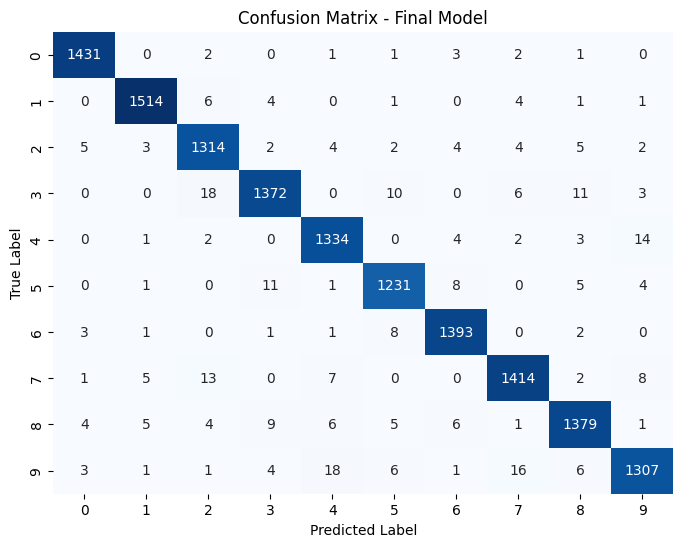

In [33]:
# Additional test on the Final model using the best performing Kernel (RBF Kernel) with Cross-Validation without scaling
svm_final = SVC(kernel='rbf', C=1.0, gamma='scale')
svm_final.fit(X_train, y_train)
y_pred_final = svm_final.predict(X_test)

# Evaluate Final Modela
SVM_accuracy = accuracy_score(y_test, y_pred_final)
print("Final Model - Classification Report:\n", classification_report(y_test, y_pred_final))
print("Final Model - Accuracy:", SVM_accuracy)

# Confusion Matrix for Final Model
cm_final = confusion_matrix(y_test, y_pred_final)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_final, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Confusion Matrix - Final Model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


In [35]:
# Cross-Validation for Final Model
cv_scores = cross_val_score(svm_final, X_train, y_train, cv=5)
print("Cross-Validation Scores:", cv_scores)
print("Mean Accuracy:", cv_scores.mean())

Cross-Validation Scores: [0.979375   0.97303571 0.98098214 0.9775     0.97598214]
Mean Accuracy: 0.977375


# Deep NN Model

In [ ]:
import tensorflow as tf
print(tf.__version__)

C:\Users\lenovo\tensorflow_env\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 19s 9ms/step - accuracy: 0.8436 - loss: 0.5259 - val_accuracy: 0.9518 - val_loss: 0.1613
Epoch 2/100
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - accuracy: 0.9627 - loss: 0.1224 - val_accuracy: 0.9608 - val_loss: 0.1283
Epoch 3/100
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 21s 8ms/step - accuracy: 0.9722 - loss: 0.0877 - val_accuracy: 0.9596 - val_loss: 0.1548
Epoch 4/100
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9786 - loss: 0.0677 - val_accuracy: 0.9674 - val_loss: 0.1274
Epoch 5/100
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - accuracy: 0.9823 - loss: 0.0560 - val_accuracy: 0.9695 - val_loss: 0.1214
Epoch 6/100
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9871 - loss: 0.0413 - val_accuracy: 0.9649 - val_loss: 0.1410
Epoch 7/100
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9871 - loss: 0.0404 - val_accuracy: 0.9674 - val_loss: 0.1414
Epoch 8/100
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9889 -

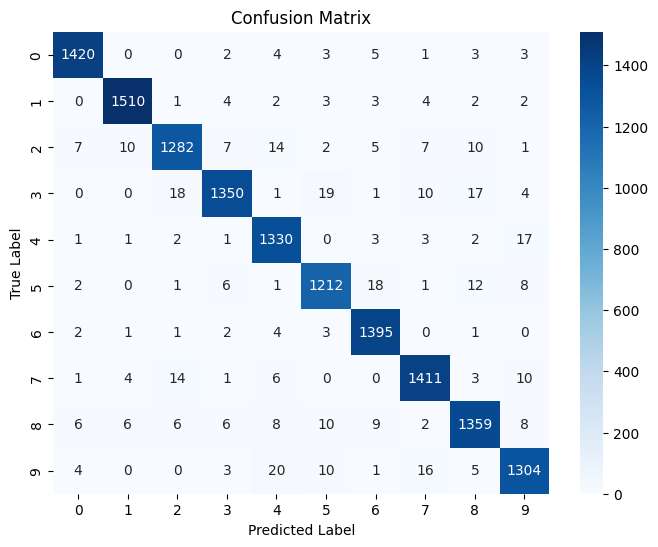

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import cross_val_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import seaborn as sns
import matplotlib.pyplot as plt

# Step 1: Load the Dataset
try:
    data = pd.read_csv("dataset_7.csv")
except FileNotFoundError:
    print("Error: The dataset file 'dataset_7.csv' was not found.")
    exit()

# Step 2: Preprocess the Data
X = data.iloc[:, 1:].values  # Features
y = data.iloc[:, 0].values   # Target

# Handle missing values
X = np.nan_to_num(X)

# Encode the target variable
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=75)

# Feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Step 3: Build the Deep Learning Model
model = Sequential()

# Network Architecture Design
model.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))  # Input and first hidden layer
model.add(Dense(32, activation='relu'))  # Second hidden layer
model.add(Dense(16, activation='relu'))  # Third hidden layer
model.add(Dense(len(np.unique(y)), activation='softmax'))  # Output layer

# Explanation: 
# - Hidden layers use ReLU for non-linear feature extraction.
# - Softmax in the output layer is suitable for multi-class classification.

# Step 4: Compile the Model
model.compile(optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Step 5: Train the Model
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_data=(X_test, y_test), callbacks=[early_stopping])

# Step 6: Evaluate the Model
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

# Step 7: Make Predictions and Calculate Metrics
y_pred = np.argmax(model.predict(X_test), axis=1)
y_test_labels = label_encoder.inverse_transform(y_test)
y_pred_labels = label_encoder.inverse_transform(y_pred)

# Metrics
DL_accuracy = accuracy_score(y_test, y_pred)
print("Classification Report:\n", classification_report(y_test, y_pred))
print("Accuracy:", DL_accuracy)

# Confusion matrix
cm = confusion_matrix(y_test_labels, y_pred_labels)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


In [54]:
from sklearn.model_selection import StratifiedKFold

# Step 8: Cross-Validation
def build_model():
    model = Sequential()
    model.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(16, activation='relu'))
    model.add(Dense(len(np.unique(y)), activation='softmax'))
    model.compile(optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=75)
cv_scores = []

for train_index, val_index in kfold.split(X, y):
    # Split the data into training and validation sets for this fold
    X_train_fold, X_val_fold = X[train_index], X[val_index]
    y_train_fold, y_val_fold = y[train_index], y[val_index]
    
    # Scale the features
    scaler = StandardScaler()
    X_train_fold = scaler.fit_transform(X_train_fold)
    X_val_fold = scaler.transform(X_val_fold)
    
    # Build and train the model
    model = build_model()
    early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    model.fit(X_train_fold, y_train_fold, epochs=100, batch_size=32, validation_data=(X_val_fold, y_val_fold), callbacks=[early_stopping], verbose=0)
    
    # Evaluate the model
    _, accuracy = model.evaluate(X_val_fold, y_val_fold, verbose=0)
    cv_scores.append(accuracy)

# Cross-validation results
print(f"Cross-Validation Scores: {cv_scores}")
print(f"Mean Accuracy: {np.mean(cv_scores) * 100:.2f}%")


C:\Users\lenovo\tensorflow_env\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
C:\Users\lenovo\tensorflow_env\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
C:\Users\lenovo\tensorflow_env\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_reg

Cross-Validation Scores: [0.9575714468955994, 0.9613571166992188, 0.961642861366272, 0.9641428589820862, 0.9632142782211304]
Mean Accuracy: 96.16%


In [ ]:

techniques = ['KNN', 'SVM', 'Deep Learning']
accuracies = [KNN_accuracy * 100, SVM_accuracy * 100, DL_accuracy * 100]  # Convert to percentages

# Create a bar chart
plt.figure(figsize=(8, 6))
plt.bar(techniques, accuracies, color=['blue', 'green', 'orange'], alpha=0.8)
plt.ylim(0, 100)  # Accuracy in percentage
plt.title('Accuracy Comparison of Classification Techniques', fontsize=14)
plt.ylabel('Accuracy (%)', fontsize=12)
plt.xlabel('Classification Technique', fontsize=12)

# Display the values on top of the bars
for i, acc in enumerate(accuracies):
    plt.text(i, acc + 1, f'{acc:.2f}%', ha='center', fontsize=10)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


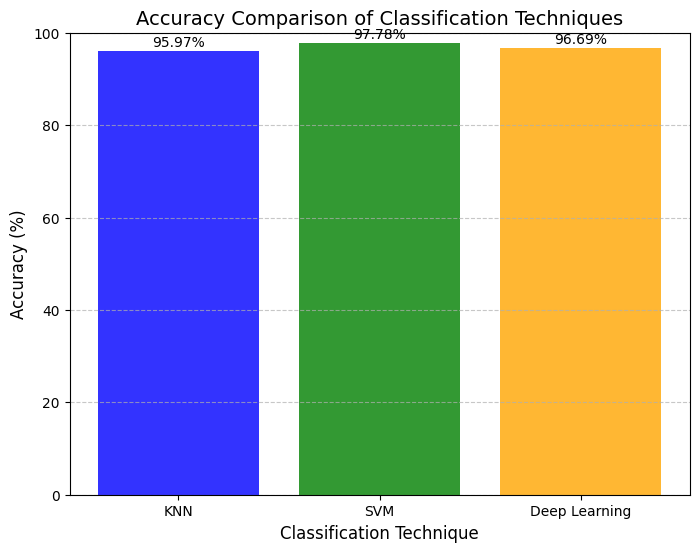